# 5.4 Confidence Intervals

**Goal:** construct and interpret confidence intervals for means, proportions, and variances.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Sampling Techniques](1_Sampling-Techniques.ipynb)
2. [Sampling Concepts](2_Sampling-Concepts.ipynb)
3. [Estimation Theory](3_Estimation-Theory.ipynb)
4. [Confidence Intervals](4_Confidence-Intervals.ipynb)
5. [Hypothesis Testing](5_Hypothesis-Testing.ipynb)
6. [Statistical Errors](6_Statistical-Errors.ipynb)
7. [Statistical Tests](7_Statistical-Tests.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Confidence Level, Confidence Interval, and Margin of Error

A confidence procedure has level 1−α if it covers the fixed target parameter in that proportion of repetitions under its assumptions, exactly or approximately as stated. After data are observed, a frequentist 95% CI is not ordinarily a posterior probability statement that the fixed parameter has 95% chance to lie between those particular endpoints.

Many intervals have estimate ± **margin of error**, but asymmetric methods do not have one universal symmetric margin. Confidence level describes procedure coverage, not the percentage of observations inside the interval. Wider intervals usually result from higher confidence, higher variability, or less independent information.

**Worked example:** with known σ=10, n=100, a 95% normal mean interval has margin 1.959964×10/10≈1.96. This quantifies sampling error under the design, not coverage or measurement bias.

In [2]:
print("Known-SD mean margin:",stats.norm.ppf(.975)*10/np.sqrt(100))

Known-SD mean margin: 1.9599639845400538


## 2. Confidence Interval for Mean

For IID normal observations and known σ, an exact interval is $\bar x\pm z_{1-α/2}\sigma/\sqrt n$. With unknown variance and IID normal observations, use $\bar x\pm t_{n-1,1-α/2}s/\sqrt n$. The t pivot is exact under that normal model; large-sample approximations can be useful beyond normality with finite variance but may be poor with strong skew, outliers, or dependence.

**Example:** compute a t interval for eight measurements. Do not choose z merely because software makes it easier. Clustered or survey-weighted means need design-aware standard errors. A confidence interval for a mean is narrower than a comparable new-observation prediction interval, which includes additional outcome variability.

In [3]:
x=np.array([8.,9.,10.,12.,16.,18.,19.,21.]);n=len(x)
se=x.std(ddof=1)/np.sqrt(n)
mean_ci=x.mean()+np.array([-1,1])*stats.t.ppf(.975,n-1)*se
print("Mean:",x.mean(),"t interval:",mean_ci)

Mean: 14.125 t interval: [ 9.94638855 18.30361145]


## 3. Confidence Interval for Proportion

For IID Bernoulli trials, p-hat=k/n. The simple Wald interval p-hat±z√[p-hat(1−p-hat)/n] can extend outside [0,1] and performs badly near boundaries or with small samples. The **Wilson score interval** is often a better approximate default:
$$center=\frac{\hat p+z²/(2n)}{1+z²/n},\quad half=\frac{z\sqrt{\hat p(1-\hat p)/n+z²/(4n²)}}{1+z²/n}.$$
An exact binomial inversion (Clopper–Pearson) is conservative due to discreteness; “exact” refers to guaranteed binomial coverage, not exact 95% coverage at every p.

**Worked example:** 0 successes in 10 trials does not establish p=0. Wilson and exact intervals retain a positive upper bound, whereas a naive Wald interval collapses to [0,0]. Unequal weights or dependent trials invalidate the simple IID binomial interpretation.

In [4]:
def wilson(k,n,confidence=.95):
    if n<=0 or not 0<=k<=n or not 0<confidence<1: raise ValueError("Invalid binomial inputs")
    p=k/n;z=stats.norm.ppf((1+confidence)/2);den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return np.array([center-half,center+half])
print("Wilson 0/10:",wilson(0,10))
print("Exact binomial 0/10:",stats.binomtest(0,10).proportion_ci(method="exact"))
assert wilson(0,10)[1]>0

Wilson 0/10: [0.        0.2775328]
Exact binomial 0/10: ConfidenceInterval(low=np.float64(0.0), high=np.float64(0.3084971078187608))


## 4. Confidence Interval for Variance

For IID **normal** observations, $(n-1)s²/\sigma²\sim\chi²_{n-1}$, giving
$$\left[\frac{(n-1)s²}{\chi²_{n-1,1-α/2}},\frac{(n-1)s²}{\chi²_{n-1,α/2}}\right].$$
Reverse the chi-square quantiles because the unknown variance is in the denominator of the pivot. Square-root endpoints give an SD interval. This result is notably sensitive to nonnormality; a large raw-data variance or heavy tails do not justify a normal chi-square pivot.

**Example:** use the eight measurements for a variance CI, explicitly as a calculation under the assumed normal model. A plot cannot prove that assumption, and its failure changes the coverage claim.

Variance interval: [ 10.9209751  103.48434186] SD interval: [ 3.30468987 10.17272539]
Simulated t-interval coverage: 0.9563333333333334


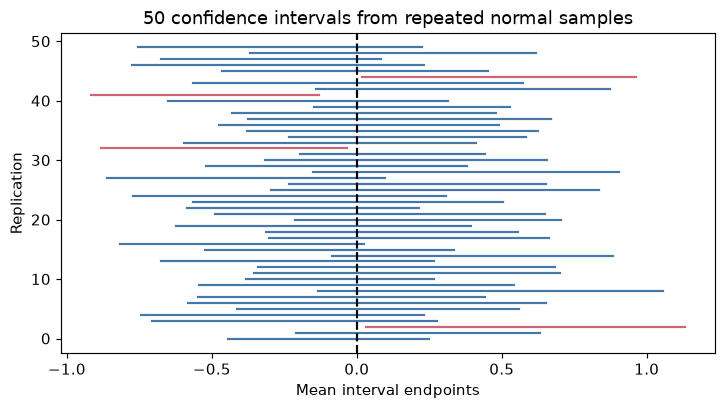

In [5]:
df=n-1;s2=x.var(ddof=1)
variance_ci=df*s2/stats.chi2.ppf([.975,.025],df)
print("Variance interval:",variance_ci,"SD interval:",np.sqrt(variance_ci))
assert variance_ci[0]<variance_ci[1]
# Repeated-sampling coverage illustration under a known normal model.
replicates=rng.normal(0,1,size=(3000,20))
means=replicates.mean(axis=1);ses=replicates.std(axis=1,ddof=1)/np.sqrt(20)
half=stats.t.ppf(.975,19)*ses
covered=(means-half<=0)&(0<=means+half)
print("Simulated t-interval coverage:",covered.mean())
fig,ax=plt.subplots()
for j in range(50):
    ax.plot([means[j]-half[j],means[j]+half[j]],[j,j],color="#4477AA" if covered[j] else "#CC6677")
ax.axvline(0,color="black",linestyle="--")
ax.set(title="50 confidence intervals from repeated normal samples",xlabel="Mean interval endpoints",ylabel="Replication")
fig.tight_layout();plt.show()

## AI/ML application and interpretation

For A/B conversion rates, provide effect intervals and denominators rather than only p-values. Intervals for two-proportion differences require a suitable two-sample or matched design; overlapping separate 95% group intervals are not a valid general significance test. For accuracy on repeated users, use clustered uncertainty rather than a naive row-level binomial CI.

## Practice

1. Interpret 95% coverage without assigning a posterior probability to a fixed parameter.
2. For known σ=8 and n=64, find the approximate 95% margin.
3. Why use Wilson instead of Wald for 1 success out of 10?
4. Which exact variance interval assumption is stronger than finite variance alone?
5. How does quadrupling IID sample size affect a mean interval's approximate margin?

## Solutions

1. Repeated applications of the procedure cover the true fixed parameter about 95% of the time under its model/design.
2. 1.959964×8/8≈1.96.
3. Wald has poor boundary coverage and may produce impossible endpoints; Wilson respects the score-inversion construction and is usually better behaved.
4. IID normal observations are required for the chi-square variance pivot.
5. It approximately halves, with unchanged scale and confidence level; finite t quantiles also change slightly.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](5_Hypothesis-Testing.ipynb).